# Experiment 3: Dimensionality Reduction Using Principal Component Analysis (PCA)

**Aim:** To perform dimensionality reduction using Principal Component Analysis (PCA) on the Titanic dataset using Python.

**Mapped CO(s):** CO2, CO4

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the Titanic Dataset

In [2]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Select Numerical Features

In [3]:
features = ["age", "fare", "sibsp", "parch", "pclass"]
X = df[features].copy()

print("Selected numerical features:", features)
print("\nOriginal shape:", X.shape)
print("\nMissing values:")
print(X.isna().sum())
X.head()

Selected numerical features: ['age', 'fare', 'sibsp', 'parch', 'pclass']

Original shape: (891, 5)

Missing values:
age       177
fare        0
sibsp       0
parch       0
pclass      0
dtype: int64


,age,fare,sibsp,parch,pclass
0,22.0,7.2500,1,0,3
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,3
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,3


## 4. Handle Missing Values

In [4]:
X_clean = X.dropna()
survived = df.loc[X_clean.index, "survived"]

print("Rows after removing missing values:", X_clean.shape[0])
print("Missing values remaining:", X_clean.isna().sum().sum())
X_clean.head()

Rows after removing missing values: 714
Missing values remaining: 0


,age,fare,sibsp,parch,pclass
0,22.0,7.2500,1,0,3
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,3
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,3


## 5. Standardize the Data

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X_clean.index)
print("Data scaled successfully")
print("\nScaled data statistics:")
X_scaled_df.describe().round(3)

Data scaled successfully

Scaled data statistics:


,age,fare,sibsp,parch,pclass
count,714.000,714.000,714.000,714.000,714.000
mean,0.000,-0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001
min,-2.017,-0.656,-0.552,-0.506,-1.476
25%,-0.660,-0.504,-0.552,-0.506,-1.476
50%,-0.117,-0.358,-0.552,-0.506,-0.283
75%,0.572,-0.025,0.525,0.667,0.911
max,3.465,9.032,4.830,6.531,0.911


## 6. Apply PCA (2 Components)

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=X_clean.index)
pca_df["survived"] = survived.values

print("Principal components generated")
print("Reduced shape:", X_pca.shape)
pca_df.head()

Principal components generated
Reduced shape: (714, 2)


,PC1,PC2,survived
0,1.133045,-0.420339,0
1,-1.460888,0.654999,1
2,0.641975,-1.048999,1
3,-1.203606,0.514642,1
4,0.302516,-1.170015,0


## 7. Explained Variance

In [7]:
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

variance_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": explained,
    "Cumulative Variance": cumulative
})

print("Explained variance ratio:")
print(variance_df.round(4))
print(f"\nTotal variance retained by 2 components: {cumulative[-1]:.4f} ({cumulative[-1]*100:.2f}%)")

Explained variance ratio:
  Principal Component  Explained Variance Ratio  Cumulative Variance
0                 PC1                    0.3483               0.3483
1                 PC2                    0.3227               0.6710

Total variance retained by 2 components: 0.6710 (67.10%)


## 8. Visualize Principal Components

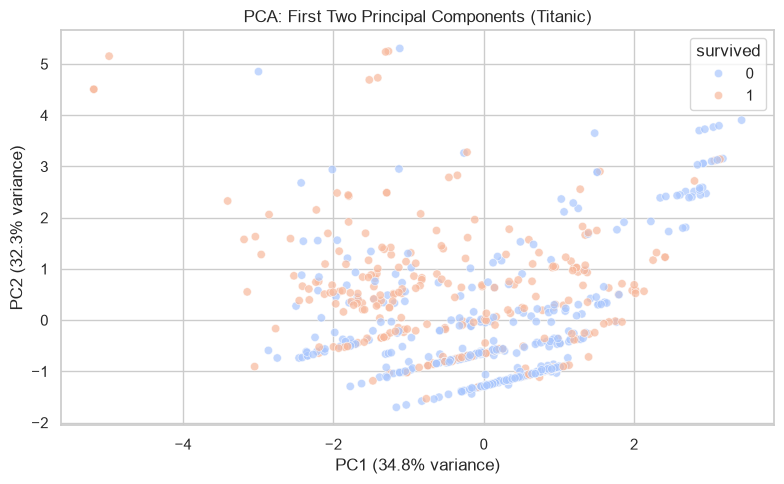

In [8]:
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="survived", palette="coolwarm", alpha=0.7)
plt.title("PCA: First Two Principal Components (Titanic)")
plt.xlabel(f"PC1 ({explained[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

In [9]:
components = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

print("Feature loadings for first two principal components:")
components.round(4)

Feature loadings for first two principal components:


,PC1,PC2
age,-0.5459,-0.1972
fare,-0.4201,0.5267
sibsp,0.3115,0.5399
parch,0.2058,0.5630
pclass,0.6213,-0.2743


---
## Exercises / Assignments

### Exercise 1: Apply PCA using three principal components

In [10]:
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

pca3_df = pd.DataFrame(X_pca3, columns=["PC1", "PC2", "PC3"], index=X_clean.index)
print("Shape after PCA with 3 components:", X_pca3.shape)
print("\nExplained variance (3 components):")
print(pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3"],
    "Explained Variance Ratio": pca3.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(pca3.explained_variance_ratio_)
}).round(4))
pca3_df.head()

Shape after PCA with 3 components: (714, 3)

Explained variance (3 components):
  Component  Explained Variance Ratio  Cumulative Variance
0       PC1                    0.3483               0.3483
1       PC2                    0.3227               0.6710
2       PC3                    0.1382               0.8092


,PC1,PC2,PC3
0,1.133045,-0.420339,-0.376889
1,-1.460888,0.654999,-0.433426
2,0.641975,-1.048999,-0.164703
3,-1.203606,0.514642,-0.459494
4,0.302516,-1.170015,0.248261


### Exercise 2: Plot the explained variance ratio of each component

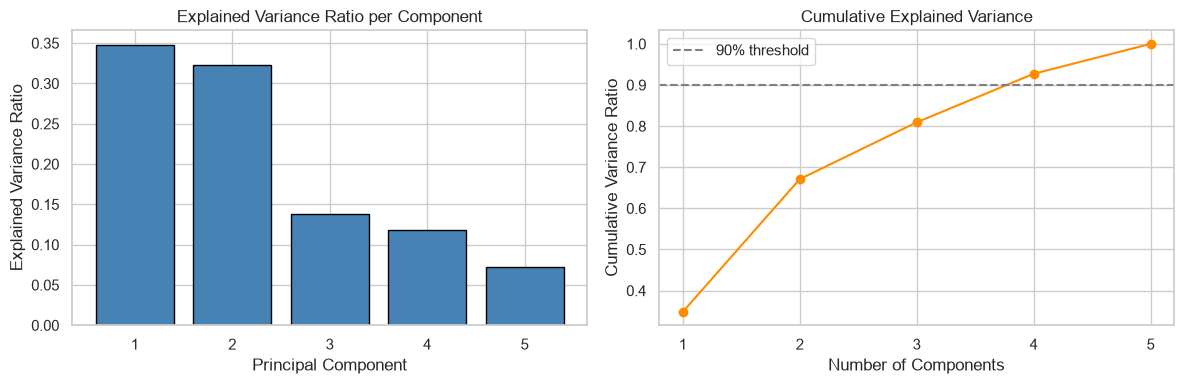

In [11]:
pca_full = PCA()
pca_full.fit(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(1, len(pca_full.explained_variance_ratio_) + 1), pca_full.explained_variance_ratio_, color="steelblue", edgecolor="black")
axes[0].set_title("Explained Variance Ratio per Component")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_xticks(range(1, len(features) + 1))

axes[1].plot(range(1, len(pca_full.explained_variance_ratio_) + 1), np.cumsum(pca_full.explained_variance_ratio_), marker="o", color="darkorange")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Variance Ratio")
axes[1].set_xticks(range(1, len(features) + 1))
axes[1].axhline(0.9, color="gray", linestyle="--", label="90% threshold")
axes[1].legend()

plt.tight_layout()
plt.show()

### Exercise 3: Compare the dataset before and after PCA

In [12]:
comparison = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Feature names",
        "Missing values",
        "Are features correlated?",
        "Variance retained"
    ],
    "Before PCA": [
        X_clean.shape[0],
        X_clean.shape[1],
        ", ".join(features),
        int(X_clean.isna().sum().sum()),
        "Yes (original features overlap)",
        "100% (spread across 5 features)"
    ],
    "After PCA (2 components)": [
        X_pca.shape[0],
        X_pca.shape[1],
        "PC1, PC2",
        0,
        "No (PC1 and PC2 are uncorrelated)",
        f"{cumulative[-1]*100:.2f}% (in 2 components)"
    ]
})

print("Dataset comparison before vs after PCA:")
display(comparison)

print("\nSample of original features (before PCA):")
display(X_clean.head())

print("Sample of principal components (after PCA):")
display(pca_df[["PC1", "PC2"]].head())

print("Correlation among original features:")
display(X_scaled_df.corr().round(3))

print("Correlation among principal components:")
display(pca_df[["PC1", "PC2"]].corr().round(3))

Dataset comparison before vs after PCA:


,Metric,Before PCA,After PCA (2 components)
0,Number of rows,714,714
1,Number of columns,5,2
2,Feature names,"age, fare, sibsp, parch, pclass","PC1, PC2"
3,Missing values,0,0
4,Are features correlated?,Yes (original features overlap),No (PC1 and PC2 are uncorrelated)
5,Variance retained,100% (spread across 5 features),67.10% (in 2 components)



Sample of original features (before PCA):


,age,fare,sibsp,parch,pclass
0,22.0,7.2500,1,0,3
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,3
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,3


Sample of principal components (after PCA):


,PC1,PC2
0,1.133045,-0.420339
1,-1.460888,0.654999
2,0.641975,-1.048999
3,-1.203606,0.514642
4,0.302516,-1.170015


Correlation among original features:


,age,fare,sibsp,parch,pclass
age,1.000,0.096,-0.308,-0.189,-0.369
fare,0.096,1.000,0.138,0.205,-0.554
sibsp,-0.308,0.138,1.000,0.384,0.067
parch,-0.189,0.205,0.384,1.000,0.026
pclass,-0.369,-0.554,0.067,0.026,1.000


Correlation among principal components:


,PC1,PC2
PC1,1.0,-0.0
PC2,-0.0,1.0


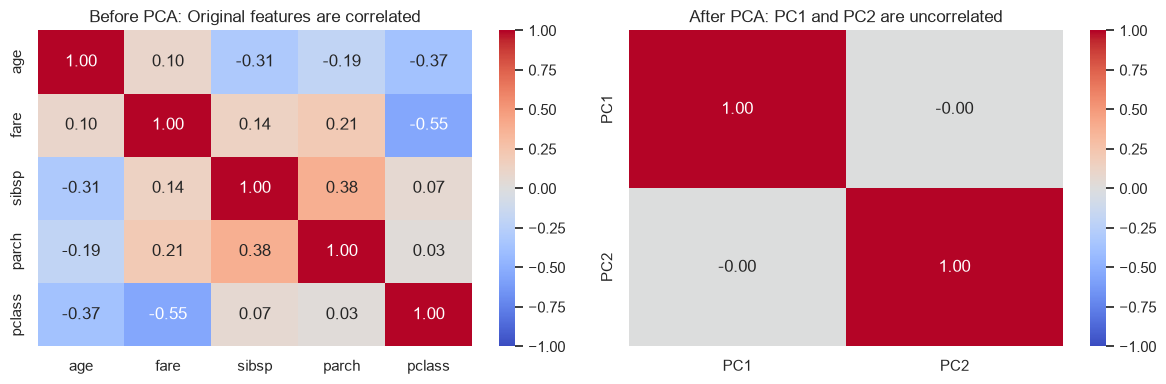

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(X_scaled_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title("Before PCA: Original features are correlated")

sns.heatmap(pca_df[["PC1", "PC2"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("After PCA: PC1 and PC2 are uncorrelated")

plt.tight_layout()
plt.show()

**Observation for Exercise 3**

- **Rows stay the same (714).** PCA transforms features, it does not add or remove passengers.
- **Columns drop from 5 to 2.** `age`, `fare`, `sibsp`, `parch`, and `pclass` are replaced by `PC1` and `PC2`.
- **Original features are correlated.** For example, fare and pclass move together (higher class usually means higher fare), so they contain overlapping information.
- **PC1 and PC2 are uncorrelated** (correlation ≈ 0). That is the point of PCA: each new axis carries a different piece of information.
- **Some information is lost.** Two components keep about **67.10%** of the total variance. The remaining ~33% is in later components. This is the usual trade-off: fewer dimensions, easier plots, but not 100% of the original detail.

### Exercise 4: Interpret the first two principal components

Feature loadings (contribution of each original feature to PC1 and PC2):


,PC1,PC2
age,-0.5459,-0.1972
fare,-0.4201,0.5267
sibsp,0.3115,0.5399
parch,0.2058,0.5630
pclass,0.6213,-0.2743



Strongest contributors (by absolute loading):
PC1: pclass    0.6213
age       0.5459
fare      0.4201
sibsp     0.3115
parch     0.2058

PC2: parch     0.5630
sibsp     0.5399
fare      0.5267
pclass    0.2743
age       0.1972

Variance explained: PC1 = 34.83%, PC2 = 32.27%
Together they retain 67.10% of the original information.


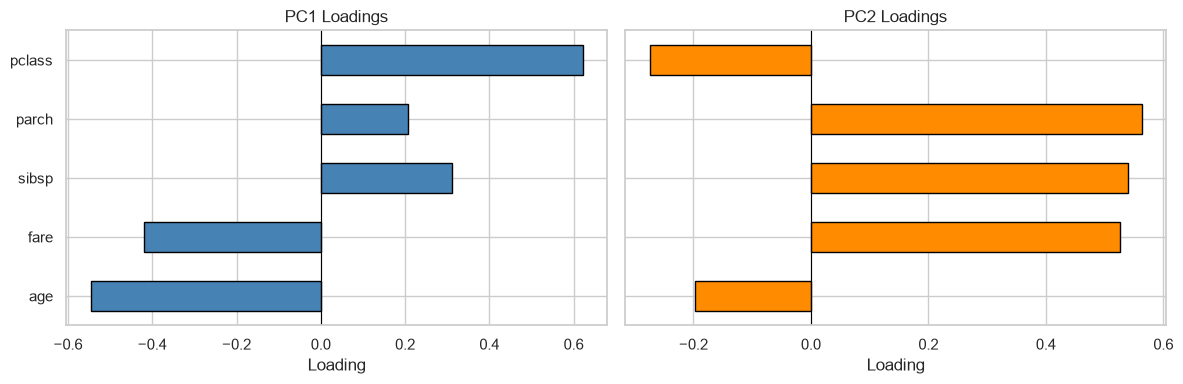

In [14]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

print("Feature loadings (contribution of each original feature to PC1 and PC2):")
display(loadings.round(4))

print("\nStrongest contributors (by absolute loading):")
print("PC1:", loadings["PC1"].abs().sort_values(ascending=False).round(4).to_string())
print("\nPC2:", loadings["PC2"].abs().sort_values(ascending=False).round(4).to_string())

print(f"\nVariance explained: PC1 = {explained[0]*100:.2f}%, PC2 = {explained[1]*100:.2f}%")
print(f"Together they retain {cumulative[-1]*100:.2f}% of the original information.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
loadings["PC1"].plot(kind="barh", ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("PC1 Loadings")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Loading")

loadings["PC2"].plot(kind="barh", ax=axes[1], color="darkorange", edgecolor="black")
axes[1].set_title("PC2 Loadings")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Loading")

plt.tight_layout()
plt.show()

**Interpretation**

Loadings show how much each original feature contributes to a principal component. A large **absolute** value means a strong contribution. Opposite signs mean those features pull the component in opposite directions.

**PC1 (34.83% of variance)** is mainly driven by **pclass** (+0.62), **age** (−0.55), and **fare** (−0.42).
- High PC1: 3rd-class passengers who are younger and paid a lower fare
- Low PC1: 1st-class passengers who are older and paid a higher fare
- So PC1 is a **socioeconomic / passenger-class axis**

**PC2 (32.27% of variance)** is mainly driven by **parch** (+0.56), **sibsp** (+0.54), and **fare** (+0.53).
- High PC2: passengers travelling with family (parents/children and siblings/spouses) who also paid more
- Low PC2: passengers travelling alone with a cheaper ticket
- So PC2 is a **family-size and spending axis**

Together, PC1 and PC2 reduce 5 correlated features to 2 uncorrelated components and retain **67.10%** of the original variance. That is enough to visualize the data, but some information is still in PC3 and beyond.

### Exercise 5: Apply PCA to another dataset (Iris)

Iris dataset shape: (150, 4)
Explained variance: [0.7296 0.2285]
Cumulative variance: [0.7296 0.9581]


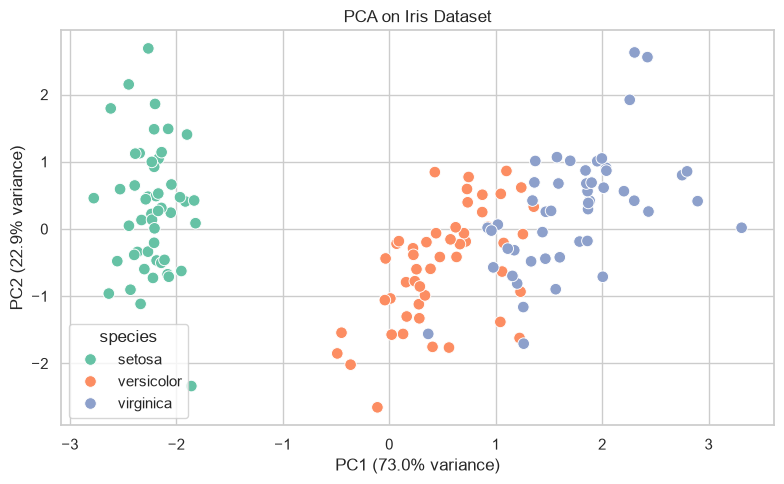

In [15]:
iris = sns.load_dataset("iris")
iris_features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X_iris = iris[iris_features]

X_iris_scaled = StandardScaler().fit_transform(X_iris)
pca_iris = PCA(n_components=2)
X_iris_pca = pca_iris.fit_transform(X_iris_scaled)

iris_pca_df = pd.DataFrame(X_iris_pca, columns=["PC1", "PC2"])
iris_pca_df["species"] = iris["species"].values

print("Iris dataset shape:", X_iris.shape)
print("Explained variance:", pca_iris.explained_variance_ratio_.round(4))
print("Cumulative variance:", np.cumsum(pca_iris.explained_variance_ratio_).round(4))

sns.scatterplot(data=iris_pca_df, x="PC1", y="PC2", hue="species", palette="Set2", s=70)
plt.title("PCA on Iris Dataset")
plt.xlabel(f"PC1 ({pca_iris.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_iris.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

---
## Observation

- Numerical features were successfully selected.
- Missing values were removed before PCA.
- Data was standardized using StandardScaler.
- PCA reduced the dataset to two principal components.
- Most of the information was retained after dimensionality reduction.
- The scatter plot clearly visualized the transformed data.

## Result

Principal Component Analysis was successfully applied to the Titanic dataset, reducing the dimensionality while preserving most of the important information.

## Conclusion

The experiment demonstrated how Principal Component Analysis (PCA) can effectively reduce the dimensionality of a dataset while retaining maximum variance. PCA simplifies data visualization, reduces computational complexity, and improves the efficiency of machine learning algorithms.